# Extrayendo contenido Cibertec
### [Página de Cursos](https://educacioncontinua.cibertec.edu.pe/buscador)
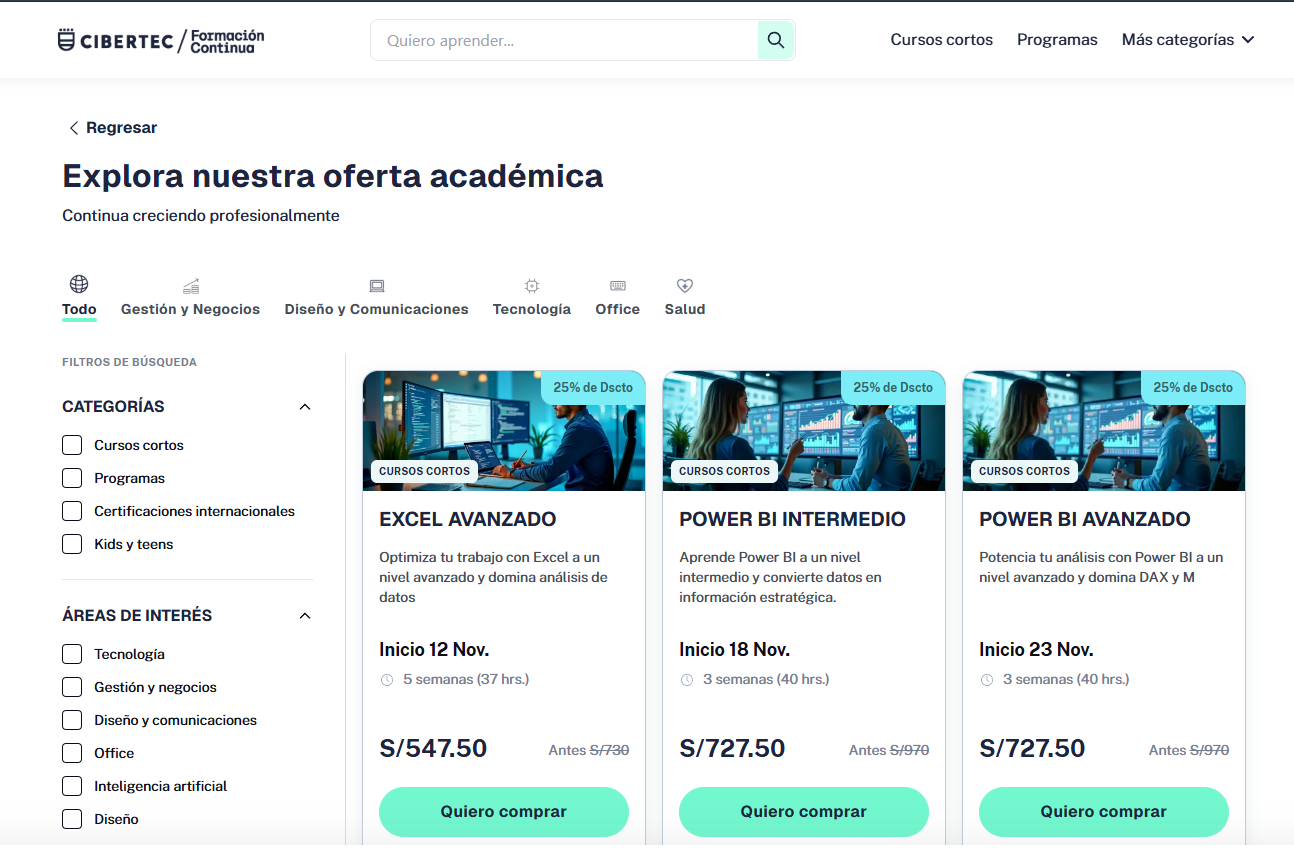

In [9]:
import os
import re
from bs4 import BeautifulSoup
import pandas as pd
from playwright.async_api import async_playwright

async def extraer_catalogo_cibertec():
    url = "https://educacioncontinua.cibertec.edu.pe/buscador/"
    cursos_capturados = {}

    async with async_playwright() as p:
        browser = await p.chromium.launch(headless=True)
        context = await browser.new_context(
            user_agent="Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
        )
        page = await context.new_page()

        print(f"Cargando {url}...")
        await page.goto(url, wait_until="networkidle")

        # Esperar a que rendericen los cursos
        await page.wait_for_selector("#catalog-cursos article", timeout=15000)

        # Detectar el total de páginas (ej. '1/11')
        total_paginas = 11
        try:
            indicador = page.locator("#catalog-cursos div:text-matches('/^\\d+\\s*\\/\\s*\\d+$/')")
            if await indicador.count() > 0:
                txt = (await indicador.first.inner_text()).strip()
                match = re.search(r'\d+\s*/\s*(\d+)', txt)
                if match:
                    total_paginas = int(match.group(1))
        except Exception:
            total_paginas = 11

        print(f"Total de páginas detectadas: {total_paginas}")

        for pag in range(1, total_paginas + 1):
            print(f"Procesando página {pag} de {total_paginas}...")

            html = await page.content()
            soup = BeautifulSoup(html, "html.parser")
            contenedor = soup.find("section", id="catalog-cursos")
            articulos = contenedor.find_all("article") if contenedor else []

            for art in articulos:
                h3 = art.find("h3")
                titulo = h3.get_text(strip=True) if h3 else None

                if not titulo or titulo in cursos_capturados:
                    continue

                # Extracción robusta de la URL del curso
                span_sm = art.find("span", string=re.compile(r"Saber\s+m[aá]s", re.I))
                if span_sm:
                    a_tag = span_sm.find_parent("a")
                    href = a_tag.get("href", "").strip() if a_tag else ""
                else:
                    a_tag = h3.find_parent("a") if h3 else None
                    href = a_tag.get("href", "").strip() if a_tag else ""

                if href:
                    url_curso = href if href.startswith("http") else f"https://educacioncontinua.cibertec.edu.pe/{href.lstrip('/')}"
                else:
                    url_curso = None

                tipo_tag = art.find("span", class_=lambda c: c and "uppercase" in c and "font-bold" in c)
                dscto_p = art.find("p", string=re.compile(r"Dscto", re.I))
                desc_p = art.find("p", class_=lambda c: c and "line-clamp-3" in c)
                inicio_p = art.find("p", string=re.compile(r"Inicio", re.I))
                duracion_span = art.find("span", string=re.compile(r"semanas|hrs|horas", re.I))
                precio_act = art.find("p", class_=lambda c: c and ("text-[24px]" in c or "leading-[22px]" in c))
                precio_ant = art.find("span", class_="line-through")
                img_tag = art.find("img")

                cursos_capturados[titulo] = {
                    "pagina": pag,
                    "titulo": titulo,
                    "tipo": tipo_tag.get_text(strip=True) if tipo_tag else None,
                    "descuento": dscto_p.get_text(strip=True) if dscto_p else None,
                    "descripcion": desc_p.get_text(strip=True) if desc_p else None,
                    "inicio": inicio_p.get_text(strip=True) if inicio_p else None,
                    "duracion": duracion_span.get_text(strip=True) if duracion_span else None,
                    "precio_actual": precio_act.get_text(strip=True) if precio_act else None,
                    "precio_regular": precio_ant.get_text(strip=True) if precio_ant else None,
                    "url_curso": url_curso,
                    "url_imagen": img_tag["src"] if img_tag and "src" in img_tag.attrs else None
                }

            # Avanzar a la siguiente página
            if pag < total_paginas:
                btn_siguiente = page.locator('button[aria-label="Ver cursos posteriores"]')
                primer_curso_previo = articulos[0].find("h3").get_text(strip=True) if articulos and articulos[0].find("h3") else ""

                await btn_siguiente.click()

                try:
                    await page.wait_for_function(
                        """(prev) => {
                            const cur = document.querySelector('#catalog-cursos article h3');
                            return cur && cur.innerText.trim() !== prev;
                        }""",
                        arg=primer_curso_previo,
                        timeout=5000
                    )
                except Exception:
                    await page.wait_for_timeout(1000)

        await browser.close()

    return pd.DataFrame(list(cursos_capturados.values()))

# Ejecutar scraping
df_cursos = await extraer_catalogo_cibertec()
print(f"\nExtracción finalizada. Total cursos: {len(df_cursos)}")

# ==========================================
# GUARDAR EN '../Data_temporal' (CSV y XLSX)
# ==========================================
output_dir = os.path.abspath("../Data_temporal")
os.makedirs(output_dir, exist_ok=True)

csv_path = os.path.join(output_dir, "catalogo_cibertec.csv")
xlsx_path = os.path.join(output_dir, "catalogo_cibertec.xlsx")

# Guardar en CSV (con encoding utf-8-sig para acentos y caracteres especiales)
df_cursos.to_csv(csv_path, index=False, encoding="utf-8-sig")
print(f"[✓] CSV guardado en: {csv_path}")

# Guardar en Excel
df_cursos.to_excel(xlsx_path, index=False, engine="openpyxl")
print(f"[✓] Excel guardado en: {xlsx_path}")

df_cursos

Cargando https://educacioncontinua.cibertec.edu.pe/buscador/...
Total de páginas detectadas: 11
Procesando página 1 de 11...
Procesando página 2 de 11...
Procesando página 3 de 11...
Procesando página 4 de 11...
Procesando página 5 de 11...
Procesando página 6 de 11...
Procesando página 7 de 11...
Procesando página 8 de 11...
Procesando página 9 de 11...
Procesando página 10 de 11...
Procesando página 11 de 11...

Extracción finalizada. Total cursos: 84
[✓] CSV guardado en: C:\Users\diego\PycharmProjects\CEEbireport\Data_temporal\catalogo_cibertec.csv
[✓] Excel guardado en: C:\Users\diego\PycharmProjects\CEEbireport\Data_temporal\catalogo_cibertec.xlsx


,pagina,titulo,tipo,descuento,descripcion,inicio,duracion,precio_actual,precio_regular,url_curso,url_imagen
0,1,EXCEL AVANZADO,CURSOS CORTOS,25% de Dscto,Optimiza tu trabajo con Excel a un nivel avanz...,Inicio 12 Nov.,5 semanas (37 hrs.),Inicio 12 Nov.,S/730,https://educacioncontinua.cibertec.edu.pe/curs...,https://a-us.storyblok.com/f/1022478/506x199/0...
1,1,POWER BI INTERMEDIO,CURSOS CORTOS,25% de Dscto,Aprende Power BI a un nivel intermedio y convi...,Inicio 18 Nov.,3 semanas (40 hrs.),Inicio 18 Nov.,S/970,https://educacioncontinua.cibertec.edu.pe/curs...,https://a-us.storyblok.com/f/1022478/506x199/7...
2,1,POWER BI AVANZADO,CURSOS CORTOS,25% de Dscto,Potencia tu análisis con Power BI a un nivel a...,Inicio 23 Nov.,3 semanas (40 hrs.),Inicio 23 Nov.,S/970,https://educacioncontinua.cibertec.edu.pe/curs...,https://a-us.storyblok.com/f/1022478/383x150/3...
3,1,ACTUALIZACIÓN EN POWER BI,PROGRAMAS,35% de Dscto,Domina Power BI en este programa y crea modelo...,Inicio 5 Nov.,14 semanas (108 hrs.),Inicio 5 Nov.,"S/2,375",https://educacioncontinua.cibertec.edu.pe/prog...,https://a-us.storyblok.com/f/1022478/383x150/0...
4,1,ESPECIALIZACIÓN EN MICROSOFT EXCEL Y GESTIÓN D...,PROGRAMAS,25% de Dscto,Aprende Excel con Power BI y VBA para gestiona...,Inicio 2 Nov.,21 semanas (209 hrs.),Inicio 2 Nov.,"S/3,025",https://educacioncontinua.cibertec.edu.pe/prog...,https://a-us.storyblok.com/f/1022478/506x199/d...
...,...,...,...,...,...,...,...,...,...,...,...
79,4,DISEÑO GRÁFICO TEENS I,KIDS & TEENS,20% de Dscto,Curso de Illustrator y Photoshop para crear il...,NaN,NaN,S/304,S/380,https://educacioncontinua.cibertec.edu.pe/kids...,https://a-us.storyblok.com/f/1022478/506x199/5...
80,4,DISEÑO GRÁFICO KIDS I,KIDS & TEENS,20% de Dscto,Aprende Illustrator y Photoshop creando ilustr...,NaN,NaN,S/304,S/380,https://educacioncontinua.cibertec.edu.pe/kids...,https://a-us.storyblok.com/f/1022478/506x199/4...
81,4,DISEÑO DE VIDEOJUEGOS CON ROBLOX,KIDS & TEENS,20% de Dscto,Aprende a crear videojuegos desde cero con Rob...,NaN,NaN,S/304,S/380,https://educacioncontinua.cibertec.edu.pe/kids...,https://a-us.storyblok.com/f/1022478/506x199/a...
82,4,CREA TU PROPIO JUEGO EN 3D,KIDS & TEENS,20% de Dscto,"Niños crean videojuegos 3D con Kodu, aprendien...",NaN,NaN,S/280,S/350,https://educacioncontinua.cibertec.edu.pe/kids...,https://a-us.storyblok.com/f/1022478/506x199/9...


In [3]:
## EXTRACCION DE CADA CURSO DEL DF DE CURSOS
import asyncio
import re
from bs4 import BeautifulSoup
import pandas as pd
from playwright.async_api import async_playwright

async def extraer_detalle_curso_completo(page, url_curso):
    """
    Navega a la URL de un curso específico, interactúa con sus módulos
    y cohortes dinámicas, y retorna un diccionario estructurado.
    """
    print(f"\n[+] Extrayendo: {url_curso}")
    data_curso = {
        "url": url_curso,
        "titulo": None,
        "tipo": None,
        "categoria": None,
        "modalidad": None,
        "certificacion": None,
        "beneficios_pago": None,
        "descripcion_corta": None,
        "descripcion_larga": None,
        "modulos": [],
        "conocimientos_previos": [],
        "requisitos_hardware": [],
        "requisitos_software": [],
        "cohortes": []
    }

    try:
        await page.goto(url_curso, wait_until="networkidle", timeout=30000)
        # Esperar a que renderice el breadcrumb / título principal
        await page.wait_for_selector("nav[aria-label='Breadcrumb']", timeout=10000)
    except Exception as e:
        print(f"[-] Error al cargar {url_curso}: {e}")
        return data_curso

    # ==========================================
    # 1. PARSEO DE DATOS ESTÁTICOS GENERALES
    # ==========================================
    html_inicial = await page.content()
    soup = BeautifulSoup(html_inicial, "html.parser")

    # Breadcrumb (Tipo y Categoría)
    nav_bc = soup.find("nav", attrs={"aria-label": "Breadcrumb"})
    if nav_bc:
        links_bc = nav_bc.find_all("a")
        # links_bc[0] -> Inicio, links_bc[1] -> Tipo, links_bc[2] -> Categoría
        if len(links_bc) > 1:
            data_curso["tipo"] = links_bc[1].get_text(strip=True)
        if len(links_bc) > 2:
            data_curso["categoria"] = links_bc[2].get_text(strip=True)

    # Título (h1)
    h1 = soup.find("h1")
    data_curso["titulo"] = h1.get_text(strip=True) if h1 else None

    # Badges de la cabecera (Modalidad, Certificado, Facilidades de pago)
    ul_badges = soup.find("ul", class_=lambda c: c and "shadow-base-shadow-subtle" in c if c else False)
    if not ul_badges:
        # Fallback por selector de items
        badges_items = soup.find_all("li", class_=lambda c: c and "shadow-base-shadow-subtle" in c if c else False)
    else:
        badges_items = ul_badges.find_all("li")

    for b in badges_items:
        txt = b.get_text(strip=True)
        txt_lower = txt.lower()
        if "virtual" in txt_lower or "presencial" in txt_lower:
            data_curso["modalidad"] = txt
        elif "certificado" in txt_lower:
            data_curso["certificacion"] = txt
        elif "cuotas" in txt_lower or "tarjeta" in txt_lower or "sin intereses" in txt_lower:
            data_curso["beneficios_pago"] = txt

    # Descripciones
    p_desc_corta = soup.find("p", class_=lambda c: c and "w-[552px]" in c if c else False)
    if p_desc_corta:
        data_curso["descripcion_corta"] = p_desc_corta.get_text(strip=True)

    p_desc_larga = soup.find("p", class_=lambda c: c and "text-base-color-neutral-100" in c and ("pensado para" in c or "ideal para" in c) if c else False)
    if not p_desc_larga:
        # Alternativa buscando párrafos con contenido explicativo amplio
        parrafos_largos = [p.get_text(strip=True) for p in soup.find_all("p") if len(p.get_text(strip=True)) > 120]
        if parrafos_largos:
            data_curso["descripcion_larga"] = parrafos_largos[0]
    else:
        data_curso["descripcion_larga"] = p_desc_larga.get_text(strip=True)

    # Conocimientos previos
    header_conocimientos = soup.find(string=re.compile(r"Conocimientos\s+previos", re.I))
    if header_conocimientos:
        parent_box = header_conocimientos.find_parent("div")
        ul_prev = parent_box.find_next("ul") if parent_box else None
        if ul_prev:
            data_curso["conocimientos_previos"] = [li.get_text(strip=True) for li in ul_prev.find_all("li")]

    # Requisitos Técnicos (Hardware y Software)
    p_hw = soup.find("p", string=re.compile(r"^Hardware$", re.I))
    if p_hw:
        parent_hw = p_hw.find_parent("div")
        ul_hw = parent_hw.find_next_sibling("ul") or parent_hw.find_next("ul")
        if ul_hw:
            data_curso["requisitos_hardware"] = [li.get_text(strip=True) for li in ul_hw.find_all("li")]

    p_sw = soup.find("p", string=re.compile(r"^Software$", re.I))
    if p_sw:
        parent_sw = p_sw.find_parent("div")
        ul_sw = parent_sw.find_next_sibling("ul") or parent_sw.find_next("ul")
        if ul_sw:
            data_curso["requisitos_software"] = [li.get_text(strip=True) for li in ul_sw.find_all("li")]

    # ==========================================
    # 2. EXTRACCIÓN DINÁMICA DE MÓDULOS (CLICKS)
    # ==========================================
    # Localizar botones de módulos (ej: 'Módulo 1', 'Módulo 2', ...)
    botones_modulos = page.locator("button:has-text('Módulo')")
    num_modulos = await botones_modulos.count()

    for idx in range(num_modulos):
        btn = botones_modulos.nth(idx)
        nombre_btn = (await btn.inner_text()).strip()

        # Clic para desplegar el contenido de este módulo
        await btn.click()
        await page.wait_for_timeout(300)

        # Leer el contenedor del módulo activo
        box_modulo = page.locator("div.border-base-color-secondary-60:has(h3)")
        if await box_modulo.count() > 0:
            html_modulo = await box_modulo.first.inner_html()
            soup_m = BeautifulSoup(html_modulo, "html.parser")

            h3_m = soup_m.find("h3")
            titulo_m = h3_m.get_text(strip=True) if h3_m else nombre_btn
            temas = [li.get_text(strip=True) for li in soup_m.find_all("li")]

            data_curso["modulos"].append({
                "modulo": nombre_btn,
                "titulo": titulo_m,
                "temas": temas
            })

    # ==========================================
    # 3. EXTRACCIÓN DINÁMICA DE COHORTES (FECHAS)
    # ==========================================
    # Localizar los labels interactivos de fechas
    labels_fechas = page.locator("div.grid label:has(span)")
    num_fechas = await labels_fechas.count()

    for idx in range(num_fechas):
        lbl = labels_fechas.nth(idx)
        fecha_txt = (await lbl.locator("span").inner_text()).strip()

        # Hacer clic en la fecha para actualizar los horarios y duraciones en pantalla
        await lbl.click()
        await page.wait_for_timeout(300)

        html_cohorte = await page.content()
        soup_c = BeautifulSoup(html_cohorte, "html.parser")

        # Buscar duración (ej: '3 semanas (40 hrs.)')
        span_dur = soup_c.find("span", string=re.compile(r"\bsemanas\b|\bhrs\b", re.I))
        duracion = span_dur.get_text(strip=True) if span_dur else None

        # Buscar horario (ej: 'Lunes, Miércoles y Viernes de 7:00 p.m. a 10:00 p.m.')
        span_horario = soup_c.find("span", string=re.compile(r"de\s+\d{1,2}:\d{2}\s*(?:a\.m\.|p\.m\.)", re.I))
        horario = span_horario.get_text(strip=True) if span_horario else None

        data_curso["cohortes"].append({
            "fecha_inicio": fecha_txt,
            "duracion": duracion,
            "horario": horario
        })

    return data_curso

In [4]:
async def procesar_todos_los_cursos(df_origen):
    todos_los_detalles = []

    # Filtrar solo URLs válidas
    urls = df_origen["url_detalle"].dropna().unique().tolist()
    total = len(urls)
    print(f"Total de cursos a procesar: {total}")

    async with async_playwright() as p:
        browser = await p.chromium.launch(headless=True)
        # Reutilizamos el contexto y la pestaña para optimizar consumo de RAM
        context = await browser.new_context(
            user_agent="Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
        )
        page = await context.new_page()

        for idx, url in enumerate(urls, 1):
            print(f"[{idx}/{total}] Procesando...")
            resultado = await extraer_detalle_curso_completo(page, url)
            todos_los_detalles.append(resultado)

            # Pausa breve entre páginas para evitar saturación
            await asyncio.sleep(1)

        await browser.close()

    return pd.DataFrame(todos_los_detalles)

# Ejecutar sobre tu dataframe previo
df_detalles = await procesar_todos_los_cursos(df_cursos)
df_detalles.head()

Total de cursos a procesar: 66
[1/66] Procesando...

[+] Extrayendo: https://educacioncontinua.cibertec.edu.pe/cursos-cortos/office/excel-avanzado-office-365/
[2/66] Procesando...

[+] Extrayendo: https://educacioncontinua.cibertec.edu.pe/cursos-cortos/tecnologia/power-bi-intermedio/
[3/66] Procesando...

[+] Extrayendo: https://educacioncontinua.cibertec.edu.pe/cursos-cortos/tecnologia/power-bi-avanzado/
[4/66] Procesando...

[+] Extrayendo: https://educacioncontinua.cibertec.edu.pe/programas/tecnologia/actualizacion-en-data-analytics-power-bi/
[5/66] Procesando...

[+] Extrayendo: https://educacioncontinua.cibertec.edu.pe/programas/office/especializacion-en-microsoft-excel-y-gestion-de-datos/
[6/66] Procesando...

[+] Extrayendo: https://educacioncontinua.cibertec.edu.pe/programas/office/actualizacion-en-microsoft-excel-intermedio-avanzado/
[7/66] Procesando...

[+] Extrayendo: https://educacioncontinua.cibertec.edu.pe/cursos-cortos/tecnologia/sql-server-2022-nivel-basico/
[8/66] Pro

,url,titulo,tipo,categoria,modalidad,certificacion,beneficios_pago,descripcion_corta,descripcion_larga,modulos,conocimientos_previos,requisitos_hardware,requisitos_software,cohortes
0,https://educacioncontinua.cibertec.edu.pe/curs...,EXCEL AVANZADO,Cursos cortos,Office,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,Domina Excel a un nivel avanzado y optimiza cá...,Domina Excel a un nivel avanzado y optimiza cá...,"[{'modulo': 'Módulo 1', 'titulo': 'Transforma ...",[CAPACITACION RECOMENDADA: - Excel Intermedio ...,[],[],"[{'fecha_inicio': '12 NOV.', 'duracion': '5 se..."
1,https://educacioncontinua.cibertec.edu.pe/curs...,POWER BI INTERMEDIO,Cursos cortos,Tecnología,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,Domina Power BI a un nivel intermedio y transf...,Domina Power BI a un nivel intermedio y transf...,"[{'modulo': 'Módulo 1', 'titulo': 'Fundamentos...",[Conocimiento de Windows a nivel de usuario fi...,"[Procesador X64: AMD Opteron, AMD Athlon 64, I...","[Windows 10 o superior (64 bits), Google Chrom...","[{'fecha_inicio': '18 NOV.', 'duracion': '3 se..."
2,https://educacioncontinua.cibertec.edu.pe/curs...,POWER BI AVANZADO,Cursos cortos,Tecnología,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,"Domina Power BI a un nivel avanzado con DAX, M...","Domina Power BI a un nivel avanzado con DAX, M...","[{'modulo': 'Módulo 1', 'titulo': 'Estrategias...","[Horario:Lunes, Miércoles y Viernes de 7:00 p....","[Procesador X64: AMD Opteron, AMD Athlon 64, I...","[Windows 10 o superior (64 bits), Google Chrom...","[{'fecha_inicio': '23 NOV.', 'duracion': '3 se..."
3,https://educacioncontinua.cibertec.edu.pe/prog...,ACTUALIZACIÓN EN POWER BI,programas,Tecnología,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,"En este programa de Power BI, aprenderás a cre...","En este programa de Power BI, aprenderás a cre...","[{'modulo': 'Módulo 1', 'titulo': 'Data Analyt...",[Conocimientos básicos en tablas y gráficos en...,"[Procesador x64: AMD Opteron, AMD Athlon 64, I...","[Windows 10 o superior (64 bits), Google Chrom...","[{'fecha_inicio': '5 NOV.', 'duracion': '14 se..."
4,https://educacioncontinua.cibertec.edu.pe/prog...,ESPECIALIZACIÓN EN MICROSOFT EXCEL Y GESTIÓN D...,programas,Office,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,Domina Excel con una especialización en anális...,Domina Excel con una especialización en anális...,"[{'modulo': 'Módulo 1', 'titulo': 'Excel Básic...",[Conocimientos básicos de Windows y manejo de ...,[],[],"[{'fecha_inicio': '2 NOV.', 'duracion': '21 se..."


In [5]:
df_detalles

,url,titulo,tipo,categoria,modalidad,certificacion,beneficios_pago,descripcion_corta,descripcion_larga,modulos,conocimientos_previos,requisitos_hardware,requisitos_software,cohortes
0,https://educacioncontinua.cibertec.edu.pe/curs...,EXCEL AVANZADO,Cursos cortos,Office,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,Domina Excel a un nivel avanzado y optimiza cá...,Domina Excel a un nivel avanzado y optimiza cá...,"[{'modulo': 'Módulo 1', 'titulo': 'Transforma ...",[CAPACITACION RECOMENDADA: - Excel Intermedio ...,[],[],"[{'fecha_inicio': '12 NOV.', 'duracion': '5 se..."
1,https://educacioncontinua.cibertec.edu.pe/curs...,POWER BI INTERMEDIO,Cursos cortos,Tecnología,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,Domina Power BI a un nivel intermedio y transf...,Domina Power BI a un nivel intermedio y transf...,"[{'modulo': 'Módulo 1', 'titulo': 'Fundamentos...",[Conocimiento de Windows a nivel de usuario fi...,"[Procesador X64: AMD Opteron, AMD Athlon 64, I...","[Windows 10 o superior (64 bits), Google Chrom...","[{'fecha_inicio': '18 NOV.', 'duracion': '3 se..."
2,https://educacioncontinua.cibertec.edu.pe/curs...,POWER BI AVANZADO,Cursos cortos,Tecnología,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,"Domina Power BI a un nivel avanzado con DAX, M...","Domina Power BI a un nivel avanzado con DAX, M...","[{'modulo': 'Módulo 1', 'titulo': 'Estrategias...","[Horario:Lunes, Miércoles y Viernes de 7:00 p....","[Procesador X64: AMD Opteron, AMD Athlon 64, I...","[Windows 10 o superior (64 bits), Google Chrom...","[{'fecha_inicio': '23 NOV.', 'duracion': '3 se..."
3,https://educacioncontinua.cibertec.edu.pe/prog...,ACTUALIZACIÓN EN POWER BI,programas,Tecnología,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,"En este programa de Power BI, aprenderás a cre...","En este programa de Power BI, aprenderás a cre...","[{'modulo': 'Módulo 1', 'titulo': 'Data Analyt...",[Conocimientos básicos en tablas y gráficos en...,"[Procesador x64: AMD Opteron, AMD Athlon 64, I...","[Windows 10 o superior (64 bits), Google Chrom...","[{'fecha_inicio': '5 NOV.', 'duracion': '14 se..."
4,https://educacioncontinua.cibertec.edu.pe/prog...,ESPECIALIZACIÓN EN MICROSOFT EXCEL Y GESTIÓN D...,programas,Office,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,Domina Excel con una especialización en anális...,Domina Excel con una especialización en anális...,"[{'modulo': 'Módulo 1', 'titulo': 'Excel Básic...",[Conocimientos básicos de Windows y manejo de ...,[],[],"[{'fecha_inicio': '2 NOV.', 'duracion': '21 se..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,https://educacioncontinua.cibertec.edu.pe/curs...,FUNDAMENTOS DE DESARROLLO EN JAVA 17,Cursos cortos,Tecnología,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,Domina la programación con un curso de Java y ...,Domina la programación con un curso de Java y ...,"[{'modulo': 'Módulo 1', 'titulo': 'Lenguaje de...","[No se requiere experiencia previa, aunque se ...",[],[],[]
62,https://educacioncontinua.cibertec.edu.pe/curs...,JAVA 17 DESARROLLO BACK-END,Cursos cortos,Tecnología,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,Desarrolla aplicaciones con un curso de Java b...,Desarrolla aplicaciones con un curso de Java b...,"[{'modulo': 'Módulo 1', 'titulo': 'Spring Core...","[Conocimiento intermedio de Windows., Conocimi...",[],[],[]
63,https://educacioncontinua.cibertec.edu.pe/curs...,IMPORTACIONES DE CHINA,Cursos cortos,Gestión y Negocios,Virtual en vivo,Certificado Cibertec,12 cuotas sin intereses* con tarjetas de Diner...,"Aprende a gestionar importaciones desde China,...","Aprende a gestionar importaciones desde China,...","[{'modulo': 'Módulo 1', 'titulo': 'Identificac...","[Manejo básico de Office recomendado, no indis.